# Практична робота №2

## Зниження розмірності, кластеризація та класифікація текстів

**Мета:** дослідити вплив PCA на класифікацію, візуалізувати дані за допомогою t-SNE, порівняти кластери K-Means зі справжніми класами та побудувати класифікатор текстових повідомлень.

**Дані:** числові ознаки та мітки з лабораторної роботи №1 (`phishing_features.csv`). Текстові URL та категоріальну ознаку `tld` не використовуємо в числовому аналізі. Для текстової частини використано SMS Spam Collection (UCI).

In [16]:
import re
import time
import zipfile
from io import BytesIO
from urllib.request import urlopen
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, adjusted_rand_score,
                             classification_report, confusion_matrix,
                             f1_score, normalized_mutual_info_score,
                             silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

## 1. Зниження розмірності

Спочатку перевіряємо розмір датасету, розподіл класів і пропущені значення. Цільова змінна `label` позначає клас URL, а решта 10 колонок є числовими ознаками.

Дані ділимо на навчальну (80 %) і тестову (20 %) вибірки. Оскільки клас 0 значно менший за клас 1, навчальну вибірку балансуємо. Тестову залишаємо з початковим співвідношенням класів.

In [17]:
from pathlib import Path

DATA_PATH = "phishing_features.csv"

if not Path(DATA_PATH).exists():
    from google.colab import files
    files.upload()

df = pd.read_csv(DATA_PATH)

y = df["label"]
feature_cols = df.select_dtypes(include="number").columns.drop("label").tolist()
X = df[feature_cols]

print("Розмір датасету:", df.shape)
print("Кількість числових ознак:", len(feature_cols))
print("Числові ознаки:", feature_cols)
print("\nКласи:")
print(y.value_counts().sort_index())
print("\nПропуски в числових ознаках:", int(X.isna().sum().sum()))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

train_df = X_train.copy()
train_df["label"] = y_train

minority = train_df[train_df["label"] == 0]
majority = train_df[train_df["label"] == 1].sample(
    n=len(minority), random_state=RANDOM_STATE
)

balanced = pd.concat([minority, majority]).sample(
    frac=1, random_state=RANDOM_STATE
)

X_balanced = balanced[feature_cols]
y_balanced = balanced["label"]

print("\nНавчальних після балансування:", len(X_balanced))
print("Тестових:", len(X_test))


Розмір датасету: (160064, 13)
Кількість числових ознак: 10
Числові ознаки: ['url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'special_char_count', 'digits_count', 'entropy']

Класи:
label
0       820
1    159244
Name: count, dtype: int64

Пропуски в числових ознаках: 0

Навчальних після балансування: 1312
Тестових: 32013


### Порівняння класифікації до і після PCA

Використовуємо Decision Tree з лабораторної роботи №1. PCA зменшує кількість ознак, зберігаючи щонайменше 95 % дисперсії навчальних даних. Порівнюємо F1 macro, кількість ознак і час навчання до та після PCA.

In [18]:
model_before = make_pipeline(
    StandardScaler(),
    DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
)

start = time.perf_counter()
model_before.fit(X_balanced, y_balanced)
time_before = time.perf_counter() - start

pred_before = model_before.predict(X_test)

model_after = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.95),
    DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
)

start = time.perf_counter()
model_after.fit(X_balanced, y_balanced)
time_after = time.perf_counter() - start

pred_after = model_after.predict(X_test)

pca = model_after.named_steps["pca"]

results_pca = pd.DataFrame({
    "Модель": ["Без PCA", "Після PCA"],
    "Кількість ознак": [X_balanced.shape[1], pca.n_components_],
    "Accuracy": [
        accuracy_score(y_test, pred_before),
        accuracy_score(y_test, pred_after)
    ],
    "F1 macro": [
        f1_score(y_test, pred_before, average="macro"),
        f1_score(y_test, pred_after, average="macro")
    ],
    "Час навчання, с": [time_before, time_after]
})

display(results_pca)

print(
    "Частка поясненої дисперсії:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

,Модель,Кількість ознак,Accuracy,F1 macro,"Час навчання, с"
0,Без PCA,10,1.00000,1.000000,0.010677
1,Після PCA,7,0.99975,0.988032,0.011314


Частка поясненої дисперсії: 0.9686


**Висновок щодо PCA.** Кількість ознак зменшилася з 10 до 7, при цьому збережено 96,86 % дисперсії. F1 macro знизився з 1,000 до 0,988, тобто для цього дерева рішень PCA трохи погіршив якість класифікації. Час навчання в цьому запуску зменшився з 0,0097 до 0,0070 с, але така мала різниця може змінюватися між запусками.

### Візуалізація даних за допомогою t-SNE

t-SNE зменшує розмірність числових даних до двох вимірів для побудови графіка. Використовуємо всі об’єкти класу 0 та таку саму кількість випадкових об’єктів класу 1. Мітки класів потрібні для кольорів на графіку, але не передаються алгоритму t-SNE.

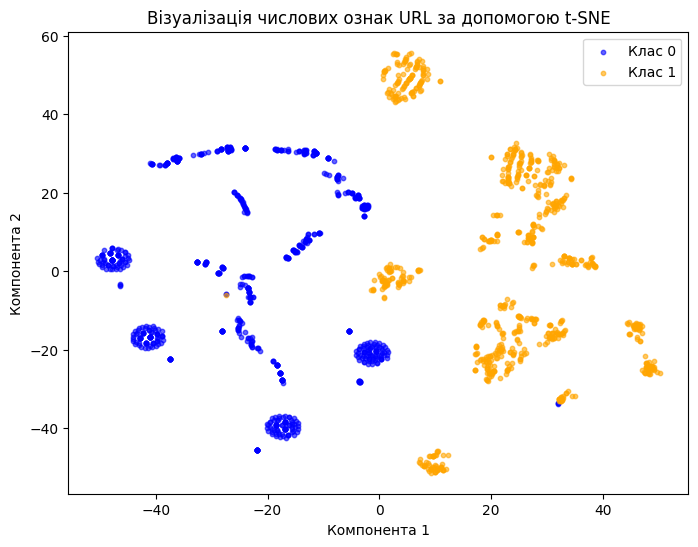

In [19]:
sample_0 = df[df["label"] == 0]

sample_1 = df[df["label"] == 1].sample(
    n=len(sample_0),
    random_state=RANDOM_STATE
)

sample = pd.concat(
    [sample_0, sample_1],
    ignore_index=True
).sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

Z = StandardScaler().fit_transform(sample[feature_cols])

tsne_points = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE
).fit_transform(Z)

plt.figure(figsize=(8, 6))

for label, color in [(0, "blue"), (1, "orange")]:
    mask = sample["label"].to_numpy() == label

    plt.scatter(
        tsne_points[mask, 0],
        tsne_points[mask, 1],
        s=10,
        alpha=0.6,
        color=color,
        label=f"Клас {label}"
    )

plt.title("Візуалізація числових ознак URL за допомогою t-SNE")
plt.xlabel("Компонента 1")
plt.ylabel("Компонента 2")
plt.legend()
plt.show()

**Висновок щодо t-SNE.** На графіку об’єкти класу 0 переважно розташовані ліворуч, а класу 1 — праворуч. Отже, на вибраній підвибірці числові ознаки добре розрізняють класи. Окремі точки розташовані поблизу іншого класу. Координати осей t-SNE не відповідають конкретним ознакам датасету.

## 2. Кластерний аналіз

K-Means групує об’єкти за схожістю числових ознак без використання міток класів. Кількість кластерів порівнюємо за Elbow Method та Silhouette Score. Після кластеризації зіставимо отримані групи зі справжніми класами.

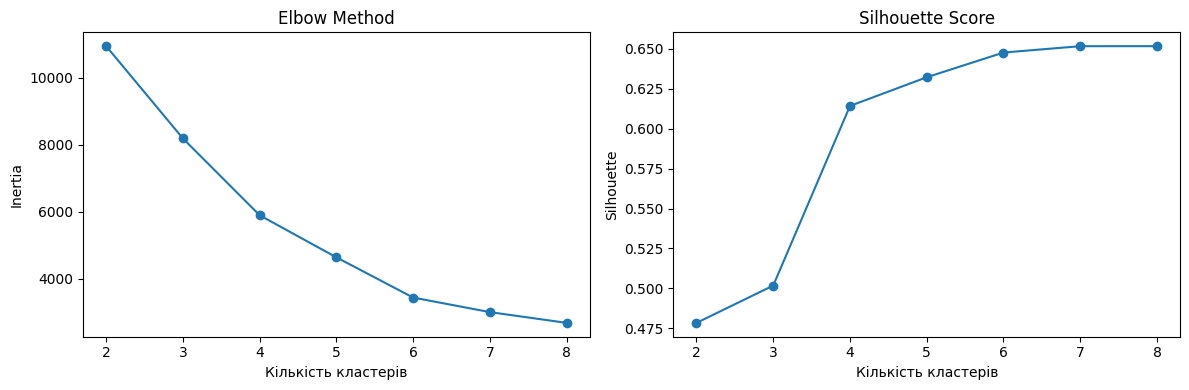

Найкраще k за Silhouette Score: 8
Найкращий Silhouette Score: 0.652


In [20]:
k_values = list(range(2, 9))
inertias = []
silhouettes = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(Z)

    inertias.append(kmeans.inertia_)
    silhouettes.append(
        silhouette_score(
            Z,
            cluster_labels,
            sample_size=1000,
            random_state=RANDOM_STATE
        )
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Кількість кластерів")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Кількість кластерів")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

best_k = k_values[np.argmax(silhouettes)]

print("Найкраще k за Silhouette Score:", best_k)
print("Найкращий Silhouette Score:", round(max(silhouettes), 3))

**Вибір кількості кластерів.** На графіку Elbow Method уповільнення зменшення Inertia помітне приблизно після 6 кластерів. Silhouette Score серед перевірених значень найбільший при 8 кластерах (0,652), хоча результати для 7 і 8 близькі. Для подальшого аналізу обрано 8 кластерів.

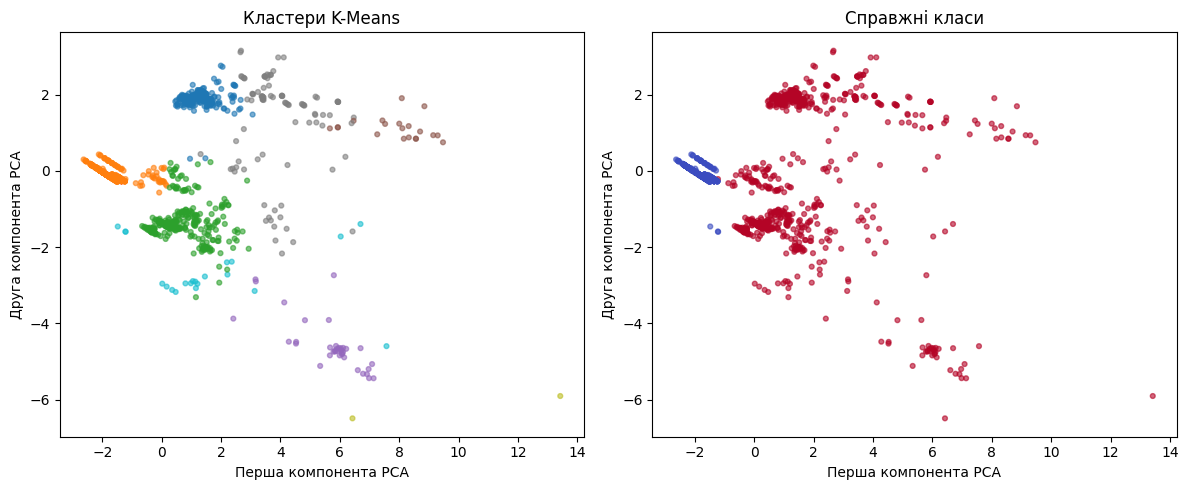

Порівняння кластерів і класів:


Справжній клас,0,1
Кластер,,
0,0,311
1,817,29
2,0,305
3,0,38
4,0,20
5,0,97
6,0,2
7,3,18


Adjusted Rand Index: 0.611


In [21]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

clusters = kmeans.fit_predict(Z)

pca_points = PCA(
    n_components=2,
    random_state=RANDOM_STATE
).fit_transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    pca_points[:, 0],
    pca_points[:, 1],
    c=clusters,
    cmap="tab10",
    s=12,
    alpha=0.6
)
axes[0].set_title("Кластери K-Means")

axes[1].scatter(
    pca_points[:, 0],
    pca_points[:, 1],
    c=sample["label"],
    cmap="coolwarm",
    s=12,
    alpha=0.6
)
axes[1].set_title("Справжні класи")

for ax in axes:
    ax.set_xlabel("Перша компонента PCA")
    ax.set_ylabel("Друга компонента PCA")

plt.tight_layout()
plt.show()

comparison = pd.crosstab(
    pd.Series(clusters, name="Кластер"),
    sample["label"].rename("Справжній клас")
)

print("Порівняння кластерів і класів:")
display(comparison)

ari = adjusted_rand_score(sample["label"], clusters)
print("Adjusted Rand Index:", round(ari, 3))

**Висновок щодо кластеризації.** Із 820 об’єктів класу 0 до одного кластера потрапили 817. Об’єкти класу 1 розподілилися між кількома кластерами. Значення ARI = 0,611 показує часткову відповідність кластерів справжнім класам. Отже, K-Means знайшов групи зі схожими числовими ознаками, але не відтворив два початкові класи.

## 3. Обробка та класифікація текстових даних

Для аналізу використано набір SMS Spam Collection. Він містить тексти повідомлень двох класів: `ham` — звичайні повідомлення та `spam` — спам. Спочатку завантажуємо дані й перевіряємо розподіл класів.

In [22]:
import zipfile
from io import BytesIO
from urllib.request import urlopen

sms_url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

with urlopen(sms_url, timeout=60) as response:
    zip_data = response.read()

with zipfile.ZipFile(BytesIO(zip_data)) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("SMSSpamCollection")
    )

    with archive.open(filename) as file:
        sms = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "text"],
            encoding="latin-1"
        )

print("Розмір датасету:", sms.shape)
print("\nРозподіл класів:")
print(sms["label"].value_counts())
print("\nПропущені значення:")
print(sms.isna().sum())

Розмір датасету: (5572, 2)

Розподіл класів:
label
ham     4825
spam     747
Name: count, dtype: int64

Пропущені значення:
label    0
text     0
dtype: int64


### Передобробка текстів

Перед аналізом переводимо текст у нижній регістр і прибираємо цифри та пунктуацію. Це допомагає рахувати однакові слова разом незалежно від написання. Стоп-слова вилучимо під час побудови хмар слів і векторизації.

In [23]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

sms["clean_text"] = sms["text"].map(clean_text)
sms = sms[sms["clean_text"].str.len() > 0].copy()

print("Кількість повідомлень після очищення:", len(sms))

Кількість повідомлень після очищення: 5569


### Хмари слів для кожного класу

Будуємо окрему хмару слів для звичайних повідомлень (`ham`) і спаму (`spam`). Частіші слова відображаються більшими. Під час побудови вилучаємо поширені англійські стоп-слова, які мало допомагають розрізняти класи.

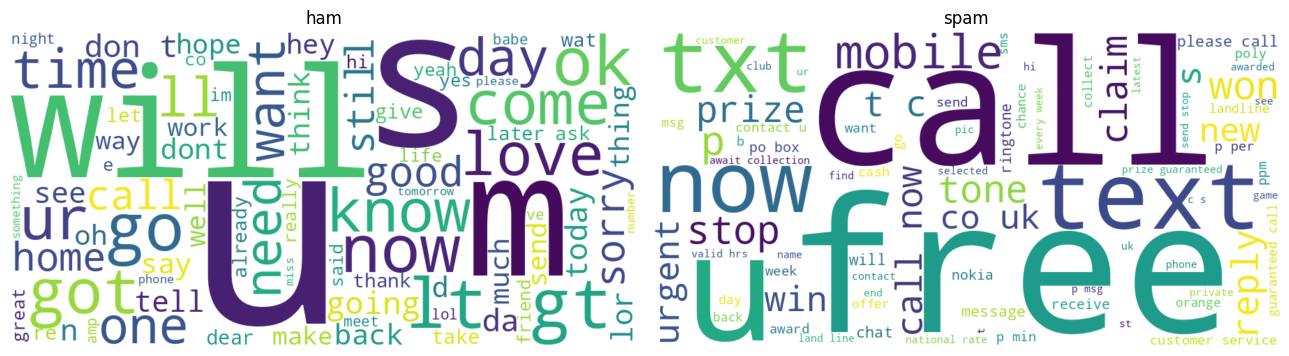

In [24]:
%pip -q install wordcloud

from wordcloud import WordCloud, STOPWORDS

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, label in zip(axes, ["ham", "spam"]):
    class_text = " ".join(
        sms.loc[sms["label"] == label, "clean_text"]
    )

    cloud = WordCloud(
        width=900,
        height=450,
        background_color="white",
        stopwords=STOPWORDS,
        max_words=80,
        random_state=RANDOM_STATE
    ).generate(class_text)

    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Результат аналізу слів.** У звичайних повідомленнях часто трапляються слова `will`, `know`, `love` і `home`, пов’язані з повсякденним спілкуванням. У спамі помітні `free`, `call`, `text`, `txt`, які часто супроводжують пропозиції та заклики до дії. Хмара показує частоту слів, а не доводить, що окреме слово зустрічається лише в одному класі.

### Векторизація та класифікація текстів

За допомогою TF-IDF перетворюємо тексти на числові ознаки. Векторизатор і модель Logistic Regression навчаємо лише на навчальній вибірці. Якість перевіряємо на тестовій вибірці за classification report, матрицею помилок і F1 macro.

In [25]:
text_train, text_test, label_train, label_test = train_test_split(
    sms["clean_text"],
    sms["label"],
    test_size=0.2,
    stratify=sms["label"],
    random_state=RANDOM_STATE
)

text_model = make_pipeline(
    TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2
    ),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
)

text_model.fit(text_train, label_train)
text_predictions = text_model.predict(text_test)

print("Звіт класифікації:")
print(classification_report(label_test, text_predictions))

print("Матриця помилок (порядок класів: ham, spam):")
print(
    confusion_matrix(
        label_test,
        text_predictions,
        labels=["ham", "spam"]
    )
)

text_f1 = f1_score(
    label_test,
    text_predictions,
    average="macro"
)

print("F1 macro:", round(text_f1, 3))

Звіт класифікації:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       965
        spam       0.94      0.91      0.92       149

    accuracy                           0.98      1114
   macro avg       0.96      0.95      0.95      1114
weighted avg       0.98      0.98      0.98      1114

Матриця помилок (порядок класів: ham, spam):
[[956   9]
 [ 14 135]]
F1 macro: 0.955


## Висновок

PCA зменшив кількість ознак URL з 10 до 7, але F1 macro дерева рішень знизився з 1,000 до 0,988. Візуалізація t-SNE показала, що об’єкти двох класів переважно утворюють окремі групи.

K-Means знайшов структуру, яка частково відповідає справжнім класам (ARI = 0,611). Більшість об’єктів класу 0 потрапили до одного кластера, тоді як клас 1 розподілився між кількома кластерами.

Для SMS класифікатор досяг F1 macro = 0,955. Він правильно визначив 135 із 149 спам-повідомлень, але пропустив 14. Отже, модель добре розрізняє звичайні повідомлення і спам, хоча частина спаму залишається нерозпізнаною.